In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/studiousdost0on/gym-rep-counter-data/squat_windows.npz
/kaggle/input/datasets/studiousdost0on/gym-rep-counter-data/landmarks_phase1/mendeley_labels.csv
/kaggle/input/datasets/studiousdost0on/gym-rep-counter-data/landmarks_phase1/subject_001_bicep_curl_bad_diagonal.parquet
/kaggle/input/datasets/studiousdost0on/gym-rep-counter-data/landmarks_phase1/subject_001_bicep_curl_bad_front.parquet
/kaggle/input/datasets/studiousdost0on/gym-rep-counter-data/landmarks_phase1/subject_001_bicep_curl_bad_side.parquet
/kaggle/input/datasets/studiousdost0on/gym-rep-counter-data/landmarks_phase1/subject_001_bicep_curl_good_diagonal.parquet
/kaggle/input/datasets/studiousdost0on/gym-rep-counter-data/landmarks_phase1/subject_001_bicep_curl_good_front.parquet
/kaggle/input/datasets/studiousdost0on/gym-rep-counter-data/landmarks_phase1/subject_001_bicep_curl_good_side.parquet
/kaggle/input/datasets/studiousdost0on/gym-rep-counter-data/landmarks_phase1/subject_001_push_up_bad_diagonal.

## Load the data

In [2]:
import os, glob
import numpy as np
import kagglehub
from sklearn.model_selection import GroupKFold

DATA_DIR = kagglehub.dataset_download('studiousdost0on/gym-rep-counter-data')
windows_file = glob.glob(f'{DATA_DIR}/**/squat_windows.npz', recursive=True)[0]
print('Data folder:', DATA_DIR)

data = np.load(windows_file)
X, y, subjects, views = data['X'], data['y'], data['subjects'], data['views']

broken_video = (subjects == 21) & (views == 'side') & (y == 0)
X, y, subjects, views = X[~broken_video], y[~broken_video], subjects[~broken_video], views[~broken_video]

person_folds = list(GroupKFold(n_splits=5).split(X, y, groups=subjects))

print(f'X: {X.shape} | bad: {y.sum()} | good: {(y == 0).sum()} | people: {len(np.unique(subjects))}')
print(f'Baseline to beat: 67% (random forest, 5 rounds by person)')

Data folder: /kaggle/input/datasets/studiousdost0on/gym-rep-counter-data
X: (3279, 30, 22) | bad: 1636 | good: 1643 | people: 25
Baseline to beat: 67% (random forest, 5 rounds by person)


## Define the model

In [4]:
import torch
from torch import nn

torch.manual_seed(42)

class FormChecker(nn.Module):
    def __init__(self, number_of_features=22, hidden_channels=64):
        super().__init__()
        self.pattern_detectors = nn.Sequential(
            nn.Conv1d(number_of_features, hidden_channels, kernel_size=5, padding=2),
            nn.BatchNorm1d(hidden_channels),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Conv1d(hidden_channels, hidden_channels, kernel_size=5, padding=2),
            nn.BatchNorm1d(hidden_channels),
            nn.ReLU(),
            nn.Dropout(0.3),
        )
        self.classifier = nn.Linear(hidden_channels, 1)

    def forward(self, windows):
        windows = windows.transpose(1, 2)
        patterns = self.pattern_detectors(windows)
        pattern_strength = patterns.mean(dim=2)
        return self.classifier(pattern_strength).squeeze(1)

test_model = FormChecker()
test_input = torch.randn(8, 30, 22)
print(f'Output shape for 8 fake pieces: {tuple(test_model(test_input).shape)}')
print(f'Number of trainable weights: {sum(p.numel() for p in test_model.parameters()):,}')


Output shape for 8 fake pieces: (8,)
Number of trainable weights: 27,969


## Train + Test, 5 rounds by person

Round 1: 68%
Round 2: 57%
Round 3: 66%
Round 4: 58%
Round 5: 62%

🧠 PyTorch FormChecker: 62% (± 4%)
🌲 Baseline to beat:     67% (± 9%)
Per view: front 66% | side 55% | diagonal 65%


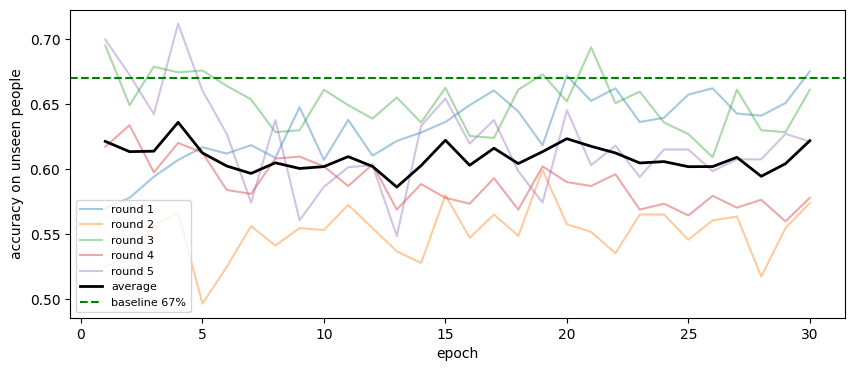

In [9]:
import matplotlib.pyplot as plt
from torch.utils.data import TensorDataset, DataLoader

EPOCHS = 30
BATCH_SIZE = 64
LEARNING_RATE = 1e-3

def train_one_round(train_index, test_index):
    torch.manual_seed(42)

    feature_mean = X[train_index].mean(axis=(0, 1), keepdims=True)
    feature_std = X[train_index].std(axis=(0, 1), keepdims=True) + 1e-6
    train_windows = torch.tensor((X[train_index] - feature_mean) / feature_std, dtype=torch.float32)
    test_windows = torch.tensor((X[test_index] - feature_mean) / feature_std, dtype=torch.float32)
    train_labels = torch.tensor(y[train_index], dtype=torch.float32)

    loader = DataLoader(TensorDataset(train_windows, train_labels), batch_size=BATCH_SIZE, shuffle=True)
    model = FormChecker()
    loss_function = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)

    test_accuracy_per_epoch = []
    for epoch in range(EPOCHS):
        model.train()
        for batch_windows, batch_labels in loader:
            logits = model(batch_windows)
            loss = loss_function(logits, batch_labels)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        # The training loop from learnpytorch.io: forward → loss → zero_grad → backward → step.

        model.eval()
        with torch.inference_mode():
            predictions = (model(test_windows) > 0).numpy().astype(int)
        test_accuracy_per_epoch.append((predictions == y[test_index]).mean())

    return predictions, test_accuracy_per_epoch

round_scores, all_curves = [], []
view_scores = {'front': [], 'side': [], 'diagonal': []}
for round_number, (train_index, test_index) in enumerate(person_folds, 1):
    predictions, curve = train_one_round(train_index, test_index)
    round_scores.append(curve[-1])
    all_curves.append(curve)
    for view in view_scores:
        view_mask = views[test_index] == view
        view_scores[view].append((predictions[view_mask] == y[test_index][view_mask]).mean())
    print(f'Round {round_number}: {curve[-1]:.0%}')
# Trains and tests on each of the same 5 person-rounds as the baseline.

print(f'\n🧠 PyTorch FormChecker: {np.mean(round_scores):.0%} (± {np.std(round_scores):.0%})')
print(f'🌲 Baseline to beat:     67% (± 9%)')
print('Per view: ' + ' | '.join(f'{view} {np.mean(scores):.0%}' for view, scores in view_scores.items()))
# The final verdict: the average over 5 rounds vs. the random forest's 67%.

plt.figure(figsize=(10, 4))
for round_number, curve in enumerate(all_curves, 1):
    plt.plot(range(1, EPOCHS + 1), curve, alpha=0.4, label=f'round {round_number}')
plt.plot(range(1, EPOCHS + 1), np.mean(all_curves, axis=0), color='black', linewidth=2, label='average')
plt.axhline(0.67, color='green', linestyle='--', label='baseline 67%')
plt.xlabel('epoch')
plt.ylabel('accuracy on unseen people')
plt.legend(fontsize=8)
plt.show()
# A chart of how test accuracy changed while training: thin lines = each round, black = the average.
# It shows whether the model is still improving, flat, or getting worse (memorizing).

### Per-video normalization (idea #1 against overfitting)
**Why:** The first CNN overfit (58% vs 67% baseline): it memorized each training person's body shape.

**What:** For every video, subtract that video's own average from all its pieces, so only the *movement* is left, not *who* is moving.

**Input:** `X` (pieces × 30 steps × 22 numbers), `subjects`, `y`, `views`

**Output:** `X` replaced by the normalized version (the original is kept as `X_original`)

**Next:** Re-run cell 3 (training) and compare with 58% (first CNN) and 67% (random forest)

**If something breaks:** Check that `video_ids` has 149 unique videos (150 minus the broken one)

In [8]:
if 'X_original' not in globals():
    X_original = X.copy()

video_ids = np.array([f'{subject}_{label}_{view}' for subject, label, view in zip(subjects, y, views)])
print(f'{len(np.unique(video_ids))} videos')

X = X_original.copy()
for video_id in np.unique(video_ids):
    pieces_of_this_video = video_ids == video_id
    video_average = X[pieces_of_this_video].mean(axis=(0, 1), keepdims=True)
    X[pieces_of_this_video] = X[pieces_of_this_video] - video_average

print(f'Before: average of the depth number differs per video by {X_original[:, :, 20].mean(axis=1).std():.3f}')
print(f'After:  {X[:, :, 20].mean(axis=1).std():.3f}  (smaller = less "who is this person" left in the data)')


149 videos
Before: average of the depth number differs per video by 0.109
After:  0.046  (smaller = less "who is this person" left in the data)


### Reusable experiment runner
**Why:** Every experiment needs the same 5-round training + chart. This avoids copying cell 3 each time.

**What:** `run_experiment(title)` trains + tests on the same 5 person-rounds using whatever is currently in `X`.

**Uses:** `train_one_round` (cell 3), `person_folds` (cell 1), `X`, `y`, `views`

**Output:** Score per round, the average ± spread, per-view scores and the accuracy-per-epoch chart

**If something breaks:** Run cells 1–3 first, since this cell needs their functions and variables

Round 1: 68%
Round 2: 57%
Round 3: 66%
Round 4: 58%
Round 5: 62%

🧠 Experiment 2: per-video normalization: 62% (± 4%)
🌲 Baseline to beat: 67% (± 9%) | first CNN: 58% (± 5%)
Per view: front 66% | side 55% | diagonal 65%


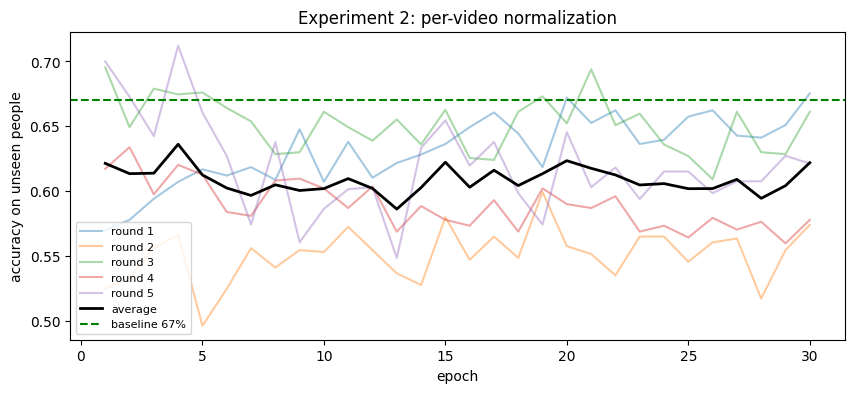

In [10]:
def run_experiment(title):
    round_scores, all_curves = [], []
    view_scores = {'front': [], 'side': [], 'diagonal': []}
    for round_number, (train_index, test_index) in enumerate(person_folds, 1):
        predictions, curve = train_one_round(train_index, test_index)
        round_scores.append(curve[-1])
        all_curves.append(curve)
        for view in view_scores:
            view_mask = views[test_index] == view
            view_scores[view].append((predictions[view_mask] == y[test_index][view_mask]).mean())
        print(f'Round {round_number}: {curve[-1]:.0%}')

    print(f'\n🧠 {title}: {np.mean(round_scores):.0%} (± {np.std(round_scores):.0%})')
    print(f'🌲 Baseline to beat: 67% (± 9%) | first CNN: 58% (± 5%)')
    print('Per view: ' + ' | '.join(f'{view} {np.mean(scores):.0%}' for view, scores in view_scores.items()))

    plt.figure(figsize=(10, 4))
    for round_number, curve in enumerate(all_curves, 1):
        plt.plot(range(1, EPOCHS + 1), curve, alpha=0.4, label=f'round {round_number}')
    plt.plot(range(1, EPOCHS + 1), np.mean(all_curves, axis=0), color='black', linewidth=2, label='average')
    plt.axhline(0.67, color='green', linestyle='--', label='baseline 67%')
    plt.title(title)
    plt.xlabel('epoch')
    plt.ylabel('accuracy on unseen people')
    plt.legend(fontsize=8)
    plt.show()

run_experiment('Experiment 2: per-video normalization')

### Mirror augmentation (idea #2 against overfitting)
**Why:** 62% after normalization, still below 67%. More varied training data = less memorizing.

**What:** Every TRAINING piece also gets a left↔right mirrored copy (test pieces stay untouched).

**How:** Swap left/right body points + angles, flip the sign of all x values and the torso lean.

**Changes:** Redefines `train_one_round` (now with `use_mirroring=True`). The next experiments use it automatically.

**If something breaks:** Check `mirror_windows` keeps the shape (pieces, 30, 22). The column order comes from `frame_features` in notebook 01.

Round 1: 63%
Round 2: 53%
Round 3: 63%
Round 4: 49%
Round 5: 73%

🧠 Experiment 3: normalization + mirroring: 60% (± 8%)
🌲 Baseline to beat: 67% (± 9%) | first CNN: 58% (± 5%)
Per view: front 62% | side 53% | diagonal 66%


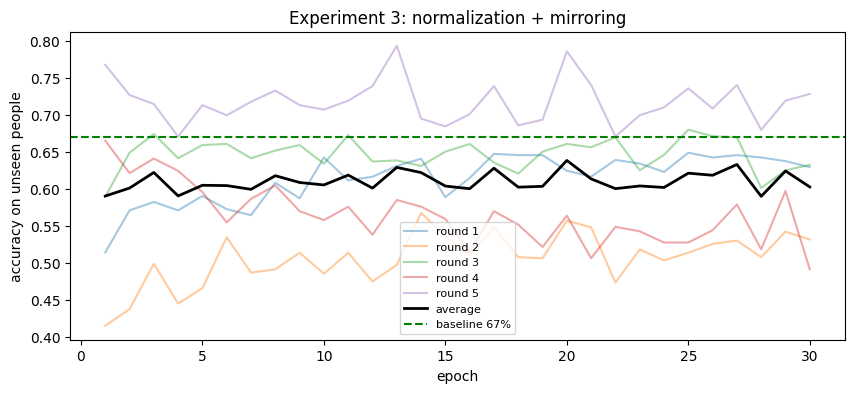

In [12]:
X_COLUMNS = [0, 2, 4, 6, 8, 10, 12, 14]
LEFT_RIGHT_PAIRS = [(0, 2), (1, 3), (4, 6), (5, 7), (8, 10), (9, 11), (12, 14), (13, 15), (16, 17), (18, 19)]
TORSO_LEAN_COLUMN = 21

def mirror_windows(windows):
    mirrored = windows.copy()
    for left_column, right_column in LEFT_RIGHT_PAIRS:
        mirrored[:, :, [left_column, right_column]] = windows[:, :, [right_column, left_column]]
    mirrored[:, :, X_COLUMNS] *= -1
    mirrored[:, :, TORSO_LEAN_COLUMN] *= -1
    return mirrored

def train_one_round(train_index, test_index, use_mirroring=True):
    torch.manual_seed(42)
    train_data, train_targets = X[train_index], y[train_index]
    if use_mirroring:
        train_data = np.concatenate([train_data, mirror_windows(train_data)])
        train_targets = np.concatenate([train_targets, train_targets])

    feature_mean = train_data.mean(axis=(0, 1), keepdims=True)
    feature_std = train_data.std(axis=(0, 1), keepdims=True) + 1e-6
    train_windows = torch.tensor((train_data - feature_mean) / feature_std, dtype=torch.float32)
    test_windows = torch.tensor((X[test_index] - feature_mean) / feature_std, dtype=torch.float32)
    train_labels = torch.tensor(train_targets, dtype=torch.float32)
    loader = DataLoader(TensorDataset(train_windows, train_labels), batch_size=BATCH_SIZE, shuffle=True)
    model = FormChecker()
    loss_function = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
    test_accuracy_per_epoch = []
    for epoch in range(EPOCHS):
        model.train()
        for batch_windows, batch_labels in loader:
            loss = loss_function(model(batch_windows), batch_labels)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        model.eval()
        with torch.inference_mode():
            predictions = (model(test_windows) > 0).numpy().astype(int)
        test_accuracy_per_epoch.append((predictions == y[test_index]).mean())
    return predictions, test_accuracy_per_epoch

run_experiment('Experiment 3: normalization + mirroring')

### What does "bad" mean in this dataset?
**Why:** 3 model experiments only moved the score by 2–4%, so the bottleneck is probably the data. The labels only say good/bad, not which mistake.

**What:** For every video, measure 5 simple things (depth, depth range, speed, sideways lean, knee width), then compare each person's GOOD video with their BAD video (same person, same camera).

**Input:** `X_original` (not normalized), `video_ids`, `subjects`, `y`, `views`

**Output:** A table: per measure, how often "bad" is lower/higher than "good" for the same person

**If something breaks:** Column numbers come from `frame_features` in notebook 01 (20 = depth, 21 = lean, 4/6 = hip x, 8/10 = knee x)

In [13]:
import pandas as pd

STEPS_PER_SECOND = 30 / 2.5
# Each piece = 30 steps over 2.5 s → 12 steps per second (used to turn "per step" into "per second").

video_measures = []
for video_id in np.unique(video_ids):
    pieces = X_original[video_ids == video_id]
    depth = pieces[:, :, 20]
    lean = pieces[:, :, 21]
    knee_width = np.abs(pieces[:, :, 8] - pieces[:, :, 10])
    hip_width = np.abs(pieces[:, :, 4] - pieces[:, :, 6])

    deep_moments = depth >= np.percentile(depth, 80)
    subject, label, view = video_id.split('_')
    video_measures.append({
        'subject': int(subject), 'quality': 'bad' if label == '1' else 'good', 'view': view,
        'max_depth': np.percentile(depth, 95),
        'depth_range': np.percentile(depth, 95) - np.percentile(depth, 5),
        'speed': np.abs(np.diff(depth, axis=1)).mean() * STEPS_PER_SECOND,
        'lean': np.abs(lean).mean(),
        'knee_to_hip_at_bottom': (knee_width[deep_moments] / (hip_width[deep_moments] + 1e-6)).mean(),
    })
video_measures = pd.DataFrame(video_measures)

paired = video_measures.pivot_table(index=['subject', 'view'], columns='quality',
                                    values=['max_depth', 'depth_range', 'speed', 'lean', 'knee_to_hip_at_bottom'])

summary_rows = []
for measure in ['max_depth', 'depth_range', 'speed', 'lean', 'knee_to_hip_at_bottom']:
    good_values, bad_values = paired[(measure, 'good')], paired[(measure, 'bad')]
    both_exist = good_values.notna() & bad_values.notna()
    difference = (bad_values - good_values)[both_exist]
    summary_rows.append({
        'measure': measure,
        'good (median)': round(good_values.median(), 2),
        'bad (median)': round(bad_values.median(), 2),
        'bad LOWER than good': f'{(difference < 0).mean():.0%}',
        'bad HIGHER than good': f'{(difference > 0).mean():.0%}',
    })
print(pd.DataFrame(summary_rows).to_string(index=False))


              measure  good (median)  bad (median) bad LOWER than good bad HIGHER than good
            max_depth           0.84          0.73                 61%                  36%
          depth_range           0.65          0.55                 61%                  36%
                speed           0.60          0.52                 72%                  26%
                 lean           0.14          0.12                 61%                  36%
knee_to_hip_at_bottom           2.01          1.80                 61%                  36%


### Get the squat videos (for watching only)
**Why:** To see with our own eyes what "bad" means (option C: quick look at ~10 people).

**What:** Re-downloads the Mendeley zip into /kaggle/temp and unpacks ONLY the 150 squat videos.

**Note:** /kaggle/temp is wiped when the session ends. That's fine, the videos are only for watching.

**If something breaks:** Internet must be ON. If the download stops halfway, delete the zip first: `!rm -f /kaggle/temp/mendeley.zip`

In [14]:
import zipfile

ZIP_PATH = '/kaggle/temp/mendeley.zip'
os.makedirs('/kaggle/temp', exist_ok=True)
if not os.path.exists(ZIP_PATH):
    !wget -q -O {ZIP_PATH} "https://data.mendeley.com/public-api/zip/kgbb3yn47p/download/2"
print(f'Zip: {os.path.getsize(ZIP_PATH) / 1e9:.1f} GB')

VIDEO_DIR = '/kaggle/temp/squat_videos'
with zipfile.ZipFile(ZIP_PATH) as archive:
    squat_files = [name for name in archive.namelist()
                   if 'Exercise Quality-wise/squat/' in name and name.endswith('.mp4')]
    for name in squat_files:
        archive.extract(name, VIDEO_DIR)
print(f'{len(squat_files)} squat videos unpacked')

def find_video(subject, quality, view):
    matches = glob.glob(f'{VIDEO_DIR}/**/subject_{subject:03d}_squat_{quality}_{view}.mp4', recursive=True)
    return matches[0] if matches else None

print('Example:', find_video(1, 'bad', 'diagonal'))

Zip: 7.6 GB
150 squat videos unpacked
Example: /kaggle/temp/squat_videos/A Multi-View Raw Video Dataset of Seven Fitness Ex/Dataset Exercise Quality-wise/squat/bad/subject_001_squat_bad_diagonal.mp4


### Watch good vs. bad side by side
**Why:** Option C: see what "bad" means for ~10 people before deciding whether to relabel.

**What:** `compare(person)` plays that person's GOOD (left) and BAD (right) squat next to each other.

**Light by design:** 240 px high, 15 fps, first 15 seconds, no sound, so the browser tab doesn't crash.

**If something breaks:** "video not found" = that person has no video for that camera, so try another view.

In [54]:
import subprocess
from IPython.display import Video
#     side    front     diagonal
def compare(subject, view='front', seconds=15):
    good_video = find_video(subject, 'good', view)
    bad_video = find_video(subject, 'bad', view)
    if not good_video or not bad_video:
        print(f'Person {subject}, {view}: video not found')
        return None
    # Finds this person's good and bad squat video for the chosen camera.

    subprocess.run([
        'ffmpeg', '-y', '-loglevel', 'error',
        '-t', str(seconds), '-i', good_video,
        '-t', str(seconds), '-i', bad_video,
        '-filter_complex', '[0:v]scale=-2:240,fps=15[good];[1:v]scale=-2:240,fps=15[bad];[good][bad]hstack=inputs=2:shortest=1',
        '-an', '-vcodec', 'libx264', '-crf', '32', '-pix_fmt', 'yuv420p', '-preset', 'veryfast',
        'compare.mp4',
    ])

    print(f'Person {subject} ({view}):   ⬅️ GOOD   |   BAD ➡️')
    return Video('compare.mp4', embed=True, width=640)

compare(1)

# person 1: too leaning forward.
# person 2: bottom of the legs lifting up, knee coming forwards too much from the side, body moving forward too much from the front 
# person 3: not dropping to the bottom enough
# person 4: not dropping to the bottom enough
# person 5: not dropping to the bottom enough, too leaning forward.
# person 6: too leaning forward.
# person 7: wrong data, the subject is doing totally another exercixe in the good- diagonal | too fast - front | the same person side
# person 8: not dropping to the bottom enough
# person 9: not dropping to the bottom enough
# person 10: too leaning forward from diagonal side and front no difference between the bad and good form
# person 11: not dropping to the bottom enough
# person 12: not dropping to the bottom enough

Person 1 (front):   ⬅️ GOOD   |   BAD ➡️


### Check curl + push-up video quality
**Why:** Before building curl/push-up counters, check whether the Mendeley videos are good enough (squats weren't).

**What:** Unpacks the bicep curl + push-up videos and upgrades `compare()` to work for any exercise.

**Judge two things:** (1) are the reps clearly visible? → counter, (2) is bad clearly different from good? → form model

**If something breaks:** The zip lives in /kaggle/temp. If the session restarted, this cell downloads it again (~2–5 min).

In [55]:
if not os.path.exists(ZIP_PATH):
    !wget -q -O {ZIP_PATH} "https://data.mendeley.com/public-api/zip/kgbb3yn47p/download/2"
# Re-downloads the zip only if it's gone (e.g. after a session restart).

VIDEO_DIR = '/kaggle/temp/exercise_videos'
with zipfile.ZipFile(ZIP_PATH) as archive:
    wanted_files = [name for name in archive.namelist()
                    if name.endswith('.mp4') and 'Exercise Quality-wise/' in name
                    and any(f'/{exercise}/' in name for exercise in ['squat', 'bicep_curl', 'push_up'])]
    for name in wanted_files:
        archive.extract(name, VIDEO_DIR)
print(f'{len(wanted_files)} videos unpacked (squat + bicep curl + push-up)')

def find_video(subject, quality, view, exercise='squat'):
    file_exercise = 'bicep' if (exercise == 'bicep_curl' and subject == 3 and quality == 'good' and view == 'side') else exercise
    matches = glob.glob(f'{VIDEO_DIR}/**/subject_{subject:03d}_{file_exercise}_{quality}_{view}.mp4', recursive=True)
    return matches[0] if matches else None

def compare(subject, exercise='squat', view='diagonal', seconds=15):
    good_video = find_video(subject, 'good', view, exercise)
    bad_video = find_video(subject, 'bad', view, exercise)
    if not good_video or not bad_video:
        print(f'Person {subject}, {exercise}, {view}: video not found')
        return None
    subprocess.run([
        'ffmpeg', '-y', '-loglevel', 'error',
        '-t', str(seconds), '-i', good_video,
        '-t', str(seconds), '-i', bad_video,
        '-filter_complex', '[0:v]scale=-2:240,fps=15[good];[1:v]scale=-2:240,fps=15[bad];[good][bad]hstack=inputs=2:shortest=1',
        '-an', '-vcodec', 'libx264', '-crf', '32', '-pix_fmt', 'yuv420p', '-preset', 'veryfast',
        'compare.mp4',
    ])
    print(f'Person {subject} · {exercise} ({view}):   ⬅️ GOOD   |   BAD ➡️')
    return Video('compare.mp4', embed=True, width=640)
 # push_up      bicep_curl
compare(10, exercise='bicep_curl',view="front" )


444 videos unpacked (squat + bicep curl + push-up)
Person 10 · bicep_curl (front):   ⬅️ GOOD   |   BAD ➡️
